In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.listdir(path='drive/MyDrive')

['Home automation',
 'wire less electricity circuit.png',
 'LDR project.gdoc',
 'inverter',
 'Slider source code.gdoc',
 'Stack_game_playing_robot_using_Arduino_By_Glen_Tech.ino.gdoc',
 '2D servo CNC plotter.txt',
 'scaner.txt',
 '100 Days of Coding in Java.pdf',
 'hackathon.png',
 'ResumeLatest.gdoc',
 'Medlink Venture Survey .gform',
 'Newspaper Club Recruitment 2024-25.csv',
 'owner talking reel final.mp4',
 'Untitled spreadsheet.gsheet',
 'cover reel.mp4',
 'rec lis.gsheet',
 'sample.gsheet',
 'TechNov.jpeg',
 'Colab Notebooks',
 'SRS File git2know (1).docx',
 'news-a-thon round 2.gdoc',
 'Untitled document.gdoc',
 'OS lab -2 .gdoc',
 'OS Lab - 3.gdoc',
 'OS Lab - 4.gdoc',
 'ganesh.gdoc',
 'STS3007 Assignemnt questions.gdoc',
 'OS Lab - 7.gdoc',
 'OS Lab - 8.gdoc',
 'OS Lab - 9.gdoc',
 'OS Lab - 10.gdoc',
 'Palm.zip',
 '23BCE8887_CN_LAB_1to5.gdoc',
 'archive.zip']

In [ ]:
import zipfile
zip_file_path = 'drive/My Drive/archive.zip'
extract_path = ''
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
  zip_ref.extractall(extract_path)
os.listdir(path='.')

['.config', 'drive', 'New_Augmented_Anemia_Dataset', 'sample_data']

In [ ]:
import os
import pandas as pd
from PIL import Image

def get_mean_rgb(image_path):
  """Calculates the mean intensity for each RGB channel of an image, ignoring pure black pixels."""
  try:
    img = Image.open(image_path).convert('RGB')
    pixels = img.getdata()
    r_sum, g_sum, b_sum = 0, 0, 0
    num_pixels = 0
    for pixel in pixels:
      # Ignore pure black pixels
      if pixel != (0, 0, 0):
        r_sum += pixel[0]
        g_sum += pixel[1]
        b_sum += pixel[2]
        num_pixels += 1

    if num_pixels == 0:
      return None, None, None # Handle cases where all pixels are black

    # Calculate mean intensity for each channel
    r_mean = r_sum / num_pixels if num_pixels > 0 else None
    g_mean = g_sum / num_pixels if num_pixels > 0 else None
    b_mean = b_sum / num_pixels if num_pixels > 0 else None

    return r_mean, g_mean, b_mean
  except Exception as e:
    print(f"Error processing image {image_path}: {e}")
    return None, None, None

def process_images_and_save_csv(anemic_folder, non_anemic_folder, output_csv_path, label_prefix=""):
  """Processes images in specified folders, calculates mean RGB, and saves to a CSV."""
  data = []
  # Process Anemic images
  for filename in os.listdir(anemic_folder):
    if filename.endswith(('.jpg', '.jpeg', '.png')):
      image_path = os.path.join(anemic_folder, filename)
      r_mean, g_mean, b_mean = get_mean_rgb(image_path)
      if r_mean is not None:
        data.append({'image_name': filename, 'label': 'Anemic', 'r_mean': r_mean, 'g_mean': g_mean, 'b_mean': b_mean})

  # Process Non-Anemic images
  for filename in os.listdir(non_anemic_folder):
    if filename.endswith(('.jpg', '.jpeg', '.png')):
      image_path = os.path.join(non_anemic_folder, filename)
      r_mean, g_mean, b_mean = get_mean_rgb(image_path)
      if r_mean is not None:
        data.append({'image_name': filename, 'label': 'Non-Anemic', 'r_mean': r_mean, 'g_mean': g_mean, 'b_mean': b_mean})

  df = pd.DataFrame(data)
  df.to_csv(output_csv_path, index=False)
  print(f"Data saved to {output_csv_path}")
  return df

# Define paths for training, testing, and validation sets
training_anemic_folder = 'New_Augmented_Anemia_Dataset/Conjuctiva/Training/Anemic'
training_non_anemic_folder = 'New_Augmented_Anemia_Dataset/Conjuctiva/Training/Non-Anemic'
testing_anemic_folder = 'New_Augmented_Anemia_Dataset/Conjuctiva/Testing/Anemic'
testing_non_anemic_folder = 'New_Augmented_Anemia_Dataset/Conjuctiva/Testing/Non-Anemic'
validation_anemic_folder = 'New_Augmented_Anemia_Dataset/Conjuctiva/Validation/Anemic'
validation_non_anemic_folder = 'New_Augmented_Anemia_Dataset/Conjuctiva/Validation/Non-Anemic'

# Process and save training data
train_df = process_images_and_save_csv(training_anemic_folder, training_non_anemic_folder, 'anemia_training_data.csv')

# Process and save testing data
test_df = process_images_and_save_csv(testing_anemic_folder, testing_non_anemic_folder, 'anemia_testing_data.csv')

# Process and save validation data
validation_df = process_images_and_save_csv(validation_anemic_folder, validation_non_anemic_folder, 'anemia_validation_data.csv')

# Display the heads of the dataframes (optional)
print("\nTraining Data Head:")
display(train_df.head())
print("\nTesting Data Head:")
display(test_df.head())
print("\nValidation Data Head:")
display(validation_df.head())

Data saved to anemia_training_data.csv
Data saved to anemia_testing_data.csv
Data saved to anemia_validation_data.csv

Training Data Head:


,image_name,label,r_mean,g_mean,b_mean
0,Anemic-167_aug11.png,Anemic,217.131591,158.463953,118.324710
1,Anemic-081_aug16.png,Anemic,191.007956,139.463078,117.921432
2,Anemic-241_aug1.png,Anemic,199.709562,131.460194,106.070872
3,Anemic-123_aug17.png,Anemic,202.290957,152.737772,152.959380
4,Anemic-211_aug13.png,Anemic,179.328222,91.009423,90.987782



Testing Data Head:


,image_name,label,r_mean,g_mean,b_mean
0,Anemic-054_aug1.png,Anemic,190.280781,124.816028,113.528519
1,Anemic-229_aug12.png,Anemic,209.119353,109.757692,105.283706
2,Anemic-171_aug4.png,Anemic,197.380469,134.386181,129.178229
3,Anemic-209 - Copy_aug13.png,Anemic,200.061406,153.766445,143.989062
4,Anemic-114_aug8.png,Anemic,171.697722,91.619399,83.166194



Validation Data Head:


,image_name,label,r_mean,g_mean,b_mean
0,Anemic-Conj-012_aug11.png,Anemic,202.208247,152.136819,140.775147
1,Anemic-138_aug16.png,Anemic,207.740564,171.124018,145.513480
2,Anemic-032_aug2.png,Anemic,138.515699,108.441130,119.939000
3,Anemic-234_aug10.png,Anemic,204.773843,87.348169,66.987606
4,Anemic-Conj-N-012_aug10.png,Anemic,212.761587,138.170867,123.470539


Test Accuracy: 0.81
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Overall Confusion Matrix:
[[405  95]
 [ 95 405]]


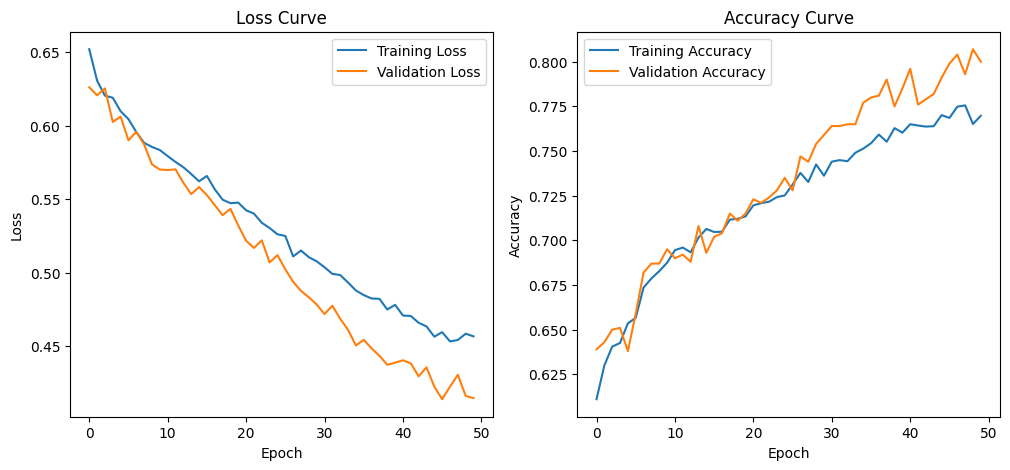

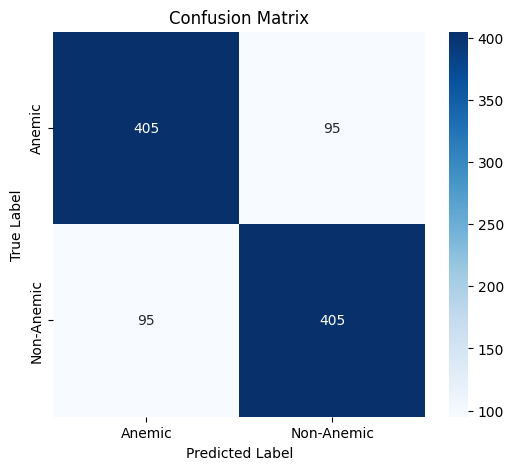

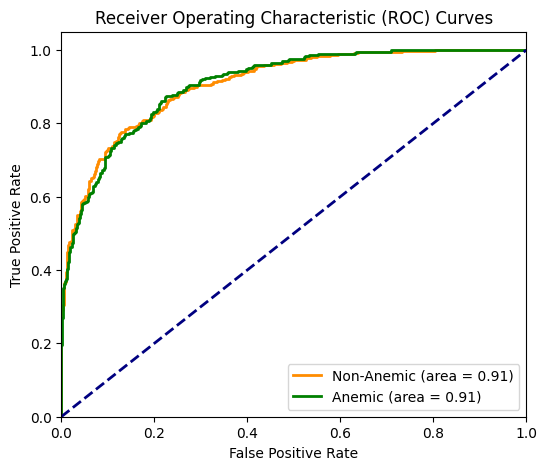

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc
import numpy as np
from skimage import color
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the CSV files
train_df = pd.read_csv('anemia_training_data.csv')
test_df = pd.read_csv('anemia_testing_data.csv')
validation_df = pd.read_csv('anemia_validation_data.csv')

# Convert RGB to LAB color space for each dataframe
# def convert_to_lab(df):
#   rgb_normalized = df[['r_mean', 'g_mean', 'b_mean']] / 255.0
#   lab_colors = color.rgb2lab(rgb_normalized)
#   df['l_mean'] = lab_colors[:, 0]
#   df['a_mean'] = lab_colors[:, 1]
#   df['b_mean_lab'] = lab_colors[:, 2]
#   return df

# train_df = convert_to_lab(train_df)
# test_df = convert_to_lab(test_df)
# validation_df = convert_to_lab(validation_df)


# Prepare the data for the ANN
# Features (X) are the mean LAB values
X_train = train_df[['r_mean', 'g_mean', 'b_mean']]
y_train = train_df['label'].apply(lambda x: 1 if x == 'Non-Anemic' else 0)

X_test = test_df[['r_mean', 'g_mean', 'b_mean']]
y_test = test_df['label'].apply(lambda x: 1 if x == 'Non-Anemic' else 0)

X_validation = validation_df[['r_mean', 'g_mean', 'b_mean']]
y_validation = validation_df['label'].apply(lambda x: 1 if x == 'Non-Anemic' else 0)


# Standardize the features using only the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_validation_scaled = scaler.transform(X_validation)

# Build the ANN model
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)), # Input layer with the correct shape
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid') # Output layer with 1 neuron and sigmoid activation for binary classification
])

# Compile the model
model.compile(optimizer='adam',
              loss='binary_crossentropy', # Binary crossentropy for binary classification
              metrics=['accuracy'])

# Train the model
# Use the validation set for monitoring during training
history = model.fit(X_train_scaled, y_train, epochs=50, batch_size=32, validation_data=(X_validation_scaled, y_validation), verbose=0)

# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Accuracy: {accuracy:.2f}")

# Predict probabilities on the test set
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int) # Convert probabilities to binary predictions

# Calculate and display the overall confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nOverall Confusion Matrix:")
print(cm)

# Plotting the loss and accuracy curves
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.savefig('loss_accuracy_curves.png') # Save the loss and accuracy plot
plt.show()

# Plotting the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Anemic', 'Non-Anemic'], yticklabels=['Anemic', 'Non-Anemic'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('confusion_matrix.png') # Save the confusion matrix plot
plt.show()

# Plotting the ROC Curves for each class on the same plot
fpr_non_anemic, tpr_non_anemic, thresholds_non_anemic = roc_curve(y_test, y_pred_prob)
roc_auc_non_anemic = auc(fpr_non_anemic, tpr_non_anemic)

# ROC for Anemic (negative class) - by flipping labels and probabilities
fpr_anemic, tpr_anemic, thresholds_anemic = roc_curve(1 - y_test, 1 - y_pred_prob)
roc_auc_anemic = auc(fpr_anemic, tpr_anemic)

plt.figure(figsize=(6, 5))
plt.plot(fpr_non_anemic, tpr_non_anemic, color='darkorange', lw=2, label=f'Non-Anemic (area = {roc_auc_non_anemic:.2f})')
plt.plot(fpr_anemic, tpr_anemic, color='green', lw=2, label=f'Anemic (area = {roc_auc_anemic:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.savefig('roc_curves.png') # Save the ROC curves plot
plt.show()